# I. Chẩn đoán bệnh tiểu đường

## 1. Định nghĩa bài toán

Mục tiêu của bài toán là xây dựng mô hình Machine Learning để dự đoán một bệnh nhân có mắc bệnh tiểu đường hay không dựa trên các thông tin về sức khỏe và đặc điểm cá nhân.

Đây là bài toán **phân loại nhị phân (Binary Classification)**.

Biến mục tiêu là `diabetes`:

- `0`: Không mắc bệnh tiểu đường.
- `1`: Mắc bệnh tiểu đường.

Quy trình thực hiện bao gồm kiểm tra dữ liệu, làm sạch dữ liệu, phân tích dữ liệu, xây dựng đặc trưng, huấn luyện nhiều mô hình, đánh giá và lựa chọn mô hình tốt nhất.

## 2. Nguồn dữ liệu

Bộ dữ liệu được sử dụng trong bài toán là: `diabetes_dataset.csv` (https://www.kaggle.com/datasets/priyamchoksi/100000-diabetes-clinical-dataset).

Dữ liệu chứa các thông tin như:

- Năm thu thập dữ liệu.
- Giới tính.
- Tuổi.
- Khu vực sinh sống.
- Chủng tộc.
- Tăng huyết áp.
- Bệnh tim.
- Lịch sử hút thuốc.
- BMI.
- HbA1c.
- Mức đường huyết.
- Trạng thái mắc bệnh tiểu đường.

Biến `diabetes` được sử dụng làm biến mục tiêu.

## 3. Tải dữ liệu

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv(r'C:\Users\Dat\Downloads\PTHTTM\DATA\diabetes_dataset.csv')

print("Đã tải dữ liệu thành công.")
print("Kích thước dữ liệu:", df.shape)

df.head()

Đã tải dữ liệu thành công.
Kích thước dữ liệu: (100000, 16)


,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


## 4. Kiểm tra dữ liệu

In [3]:
print("Kích thước dữ liệu:")
print(df.shape)

print("\nTên các cột:")
print(df.columns.tolist())

print("\nThông tin dữ liệu:")
df.info()

print("\nThống kê mô tả:")
display(df.describe(include="all").T)

Kích thước dữ liệu:
(100000, 16)

Tên các cột:
['year', 'gender', 'age', 'location', 'race:AfricanAmerican', 'race:Asian', 'race:Caucasian', 'race:Hispanic', 'race:Other', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'hbA1c_level', 'blood_glucose_level', 'diabetes']

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   year                  100000 non-null  int64  
 1   gender                100000 non-null  str    
 2   age                   100000 non-null  float64
 3   location              100000 non-null  str    
 4   race:AfricanAmerican  100000 non-null  int64  
 5   race:Asian            100000 non-null  int64  
 6   race:Caucasian        100000 non-null  int64  
 7   race:Hispanic         100000 non-null  int64  
 8   race:Other            100000 non-null  int64  
 9   hypertension          1

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,100000.0,NaN,NaN,NaN,2018.36082,1.345239,2015.0,2019.0,2019.0,2019.0,2022.0
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
location,100000,55,Hawaii,2038,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race:AfricanAmerican,100000.0,NaN,NaN,NaN,0.20223,0.401665,0.0,0.0,0.0,0.0,1.0
race:Asian,100000.0,NaN,NaN,NaN,0.20015,0.400114,0.0,0.0,0.0,0.0,1.0
race:Caucasian,100000.0,NaN,NaN,NaN,0.19876,0.399069,0.0,0.0,0.0,0.0,1.0
race:Hispanic,100000.0,NaN,NaN,NaN,0.19888,0.39916,0.0,0.0,0.0,0.0,1.0
race:Other,100000.0,NaN,NaN,NaN,0.19998,0.399987,0.0,0.0,0.0,0.0,1.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0


Bảng trên cung cấp các thống kê mô tả cơ bản cho cả biến số và biến phân loại trong bộ dữ liệu.

### Ý nghĩa các chỉ số

- **count**: Số lượng giá trị không bị thiếu của biến.
- **unique**: Số lượng giá trị khác nhau, chỉ áp dụng chủ yếu cho biến phân loại.
- **top**: Giá trị xuất hiện nhiều nhất.
- **freq**: Số lần xuất hiện của giá trị phổ biến nhất (`top`).
- **mean**: Giá trị trung bình của biến số.
- **std**: Độ lệch chuẩn, thể hiện mức độ phân tán của dữ liệu quanh giá trị trung bình.
- **min**: Giá trị nhỏ nhất.
- **25% (Q1)**: 25% dữ liệu có giá trị nhỏ hơn hoặc bằng mức này.
- **50% (Median - Q2)**: Trung vị, 50% dữ liệu nằm dưới và 50% nằm trên giá trị này.
- **75% (Q3)**: 75% dữ liệu có giá trị nhỏ hơn hoặc bằng mức này.
- **max**: Giá trị lớn nhất.

Các giá trị `NaN` trong bảng không nhất thiết có nghĩa là dữ liệu bị thiếu. Ví dụ, các chỉ số như `mean`, `std`, `min`, `max` không được tính cho các biến dạng chuỗi như `gender`, `location` và `smoking_history`.

## 5. Phân tích chất lượng dữ liệu

Chất lượng dữ liệu có ảnh hưởng trực tiếp đến kết quả của mô hình Machine Learning.

Trong phần này, dữ liệu được kiểm tra tổng quát dựa trên:

- Kiểu dữ liệu.
- Số giá trị duy nhất.
- Số lượng giá trị thiếu.
- Tỷ lệ giá trị thiếu.
- Số lượng dòng bị trùng lặp.

In [4]:
quality_report = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes,
    "Số giá trị khác nhau": df.nunique(),
    "Số giá trị thiếu": df.isnull().sum(),
    "Tỷ lệ thiếu (%)": df.isnull().mean() * 100
})

display(quality_report)

print("Số dòng trùng lặp:", df.duplicated().sum())

,Kiểu dữ liệu,Số giá trị khác nhau,Số giá trị thiếu,Tỷ lệ thiếu (%)
year,int64,7,0,0.0
gender,str,3,0,0.0
age,float64,102,0,0.0
location,str,55,0,0.0
race:AfricanAmerican,int64,2,0,0.0
race:Asian,int64,2,0,0.0
race:Caucasian,int64,2,0,0.0
race:Hispanic,int64,2,0,0.0
race:Other,int64,2,0,0.0
hypertension,int64,2,0,0.0


Số dòng trùng lặp: 14


## 6. Phân tích giá trị thiếu

Giá trị thiếu có thể làm ảnh hưởng đến việc phân tích và huấn luyện mô hình.

Ở bước này:

- Kiểm tra số lượng giá trị `NaN` của từng cột.
- Tính tỷ lệ giá trị thiếu.
- Kiểm tra các giá trị đặc biệt có thể mang ý nghĩa thiếu thông tin.

In [5]:
missing_report = pd.DataFrame({
    "Số lượng thiếu": df.isnull().sum(),
    "Tỷ lệ thiếu (%)": df.isnull().mean() * 100
})

missing_report = missing_report.sort_values(
    "Số lượng thiếu",
    ascending=False
)

display(missing_report)

print(
    "Số bản ghi smoking_history = 'No Info':",
    (df["smoking_history"] == "No Info").sum()
)

,Số lượng thiếu,Tỷ lệ thiếu (%)
year,0,0.0
gender,0,0.0
age,0,0.0
location,0,0.0
race:AfricanAmerican,0,0.0
race:Asian,0,0.0
race:Caucasian,0,0.0
race:Hispanic,0,0.0
race:Other,0,0.0
hypertension,0,0.0


Số bản ghi smoking_history = 'No Info': 35816


## 7. Phân tích dữ liệu trùng lặp

Các bản ghi trùng lặp có thể khiến một số quan sát được tính nhiều lần và làm sai lệch quá trình học của mô hình.

Trong bước này:
- Đếm số dòng bị trùng.
- Quan sát các dòng trùng lặp.
- Loại bỏ các bản ghi trùng hoàn toàn.

In [8]:
duplicate_count = df.duplicated().sum()

print("Số dòng trùng lặp:", duplicate_count)

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(20))

df = df.drop_duplicates().reset_index(drop=True)

print("Kích thước sau khi loại duplicate:", df.shape)

Số dòng trùng lặp: 14


,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
2782,2019,Male,40.0,Alaska,0,0,1,0,0,0,0,No Info,27.32,6.2,85,0
2848,2019,Male,40.0,Alaska,0,0,1,0,0,0,0,No Info,27.32,6.2,85,0
21379,2019,Male,65.0,Georgia,0,1,0,0,0,0,0,No Info,27.32,4.0,90,0
21662,2019,Male,65.0,Georgia,0,1,0,0,0,0,0,No Info,27.32,4.0,90,0
23282,2019,Female,21.0,Guam,0,1,0,0,0,0,0,never,27.32,6.6,155,0
23313,2019,Female,21.0,Guam,0,1,0,0,0,0,0,never,27.32,6.6,155,0
32127,2019,Male,13.0,Iowa,0,1,0,0,0,0,0,No Info,27.32,4.8,160,0
33506,2019,Male,13.0,Iowa,0,1,0,0,0,0,0,No Info,27.32,4.8,160,0
42946,2019,Male,46.0,Maryland,0,1,0,0,0,0,0,never,27.32,6.6,90,0
43401,2019,Male,46.0,Maryland,0,1,0,0,0,0,0,never,27.32,6.6,90,0


Kích thước sau khi loại duplicate: (99986, 16)


## 8. Phân tích giá trị không hợp lệ

Giá trị không hợp lệ là các giá trị không phù hợp với ý nghĩa của biến.

Một số điều kiện được kiểm tra:

- Tuổi phải nằm trong phạm vi hợp lý.
- BMI phải lớn hơn 0.
- HbA1c phải lớn hơn 0.
- Mức đường huyết phải lớn hơn 0.
- `hypertension`, `heart_disease` và `diabetes` chỉ nhận 0 hoặc 1.
- Các biến chủng tộc phải có giá trị 0 hoặc 1.
- Mỗi bệnh nhân chỉ thuộc một nhóm chủng tộc.

In [9]:
race_cols = [col for col in df.columns if col.startswith("race:")]

invalid_checks = {
    "age không hợp lệ":
        ~df["age"].between(0, 120),

    "bmi không hợp lệ":
        df["bmi"] <= 0,

    "HbA1c không hợp lệ":
        df["hbA1c_level"] <= 0,

    "blood glucose không hợp lệ":
        df["blood_glucose_level"] <= 0,

    "hypertension không hợp lệ":
        ~df["hypertension"].isin([0, 1]),

    "heart_disease không hợp lệ":
        ~df["heart_disease"].isin([0, 1]),

    "target không hợp lệ":
        ~df["diabetes"].isin([0, 1]),

    "race không đúng one-hot":
        df[race_cols].sum(axis=1) != 1
}

for name, condition in invalid_checks.items():
    print(f"{name}: {condition.sum()} bản ghi")

age không hợp lệ: 0 bản ghi
bmi không hợp lệ: 0 bản ghi
HbA1c không hợp lệ: 0 bản ghi
blood glucose không hợp lệ: 0 bản ghi
hypertension không hợp lệ: 0 bản ghi
heart_disease không hợp lệ: 0 bản ghi
target không hợp lệ: 0 bản ghi
race không đúng one-hot: 0 bản ghi


## 9. Phân tích ngoại lệ

Ngoại lệ là các giá trị nằm cách xa phần lớn các quan sát khác.

Phương pháp IQR được sử dụng để phát hiện ngoại lệ cho các biến số:

- `age`
- `bmi`
- `hbA1c_level`
- `blood_glucose_level`

Một giá trị được xem là ngoại lệ nếu nhỏ hơn:

`Q1 - 1.5 × IQR`

hoặc lớn hơn:

`Q3 + 1.5 × IQR`

In [10]:
numeric_check_cols = [
    "age",
    "bmi",
    "hbA1c_level",
    "blood_glucose_level"
]

outlier_summary = []

for col in numeric_check_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Biến": col,
        "Lower bound": lower,
        "Upper bound": upper,
        "Số outlier": count
    })

display(pd.DataFrame(outlier_summary))

,Biến,Lower bound,Upper bound,Số outlier
0,age,-30.000,114.000,0
1,bmi,14.705,38.505,7086
2,hbA1c_level,2.700,8.300,1315
3,blood_glucose_level,11.500,247.500,2038


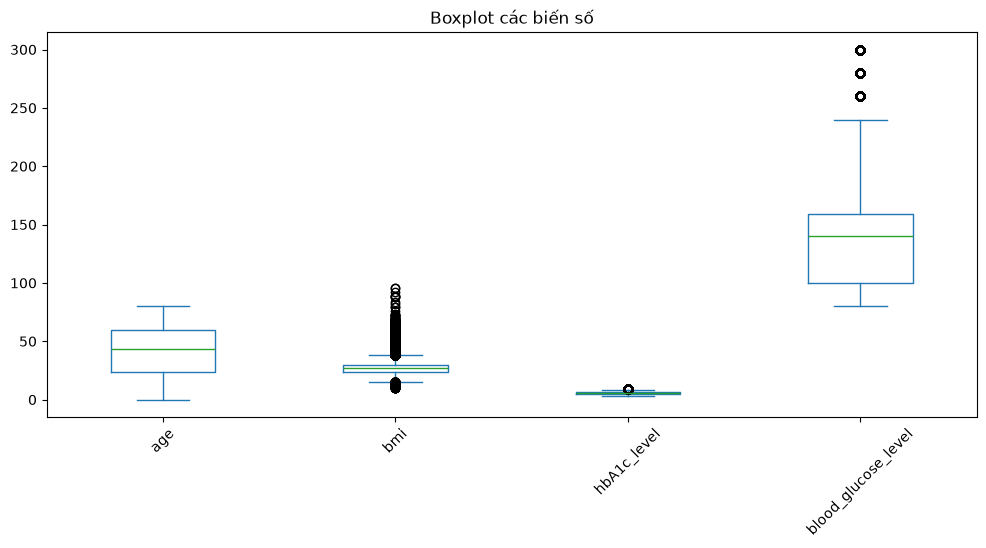

In [11]:
df[numeric_check_cols].plot(
    kind="box",
    figsize=(12, 5),
    subplots=False
)

plt.title("Boxplot các biến số")
plt.xticks(rotation=45)
plt.show()

Boxplot được dùng để phát hiện các giá trị ngoại lệ:

- `age`: không có outlier.
- `bmi`: có **7.086 outlier** (~7,09%), nhiều nhất trong các biến.
- `hbA1c_level`: có **1.315 outlier** (~1,32%).
- `blood_glucose_level`: có **2.038 outlier** (~2,04%).

Các giá trị outlier chủ yếu nằm ở mức cao.

Tuy nhiên, trong dữ liệu y tế, outlier không nhất thiết là dữ liệu sai. BMI, HbA1c hoặc đường huyết cao có thể là dấu hiệu quan trọng của bệnh tiểu đường.

## 10. Phân tích khám phá dữ liệu (EDA)

EDA tập trung vào:
- Phân bố của biến mục tiêu.
- Phân bố các đặc trưng quan trọng.
- Mối quan hệ giữa đặc trưng và biến mục tiêu.
- Phân tích tương quan.

Số lượng:
diabetes
0    91486
1     8500
Name: count, dtype: int64

Tỷ lệ (%):
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


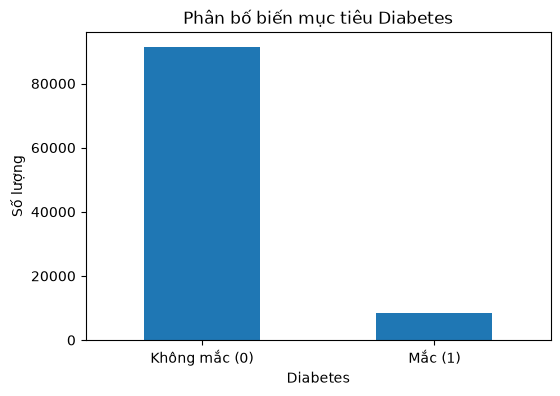

In [12]:
target_counts = df["diabetes"].value_counts().sort_index()
target_percent = df["diabetes"].value_counts(normalize=True).sort_index() * 100

print("Số lượng:")
print(target_counts)

print("\nTỷ lệ (%):")
print(target_percent.round(2))

plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")

plt.title("Phân bố biến mục tiêu Diabetes")
plt.xlabel("Diabetes")
plt.ylabel("Số lượng")
plt.xticks([0, 1], ["Không mắc (0)", "Mắc (1)"], rotation=0)

plt.show()

 Khoảng **91,5%** bệnh nhân thuộc lớp `0` và chỉ khoảng **8,5%** thuộc lớp `1`.
Bộ dữ liệu có hiện tượng **mất cân bằng lớp (class imbalance)** khá rõ rệt.

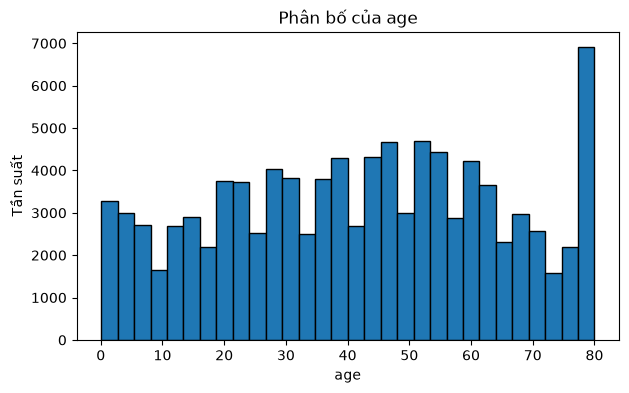

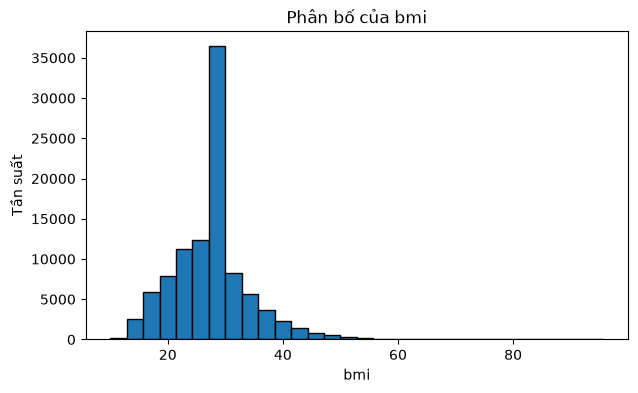

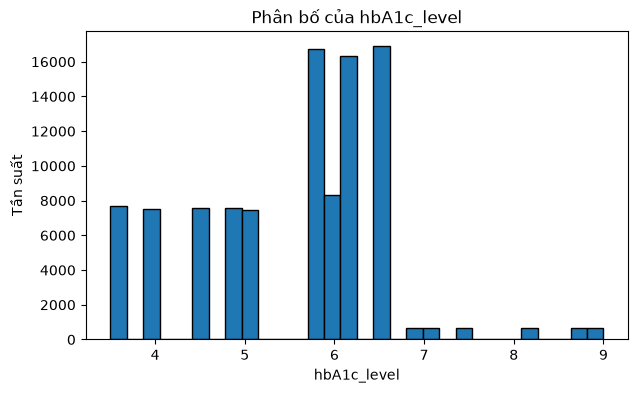

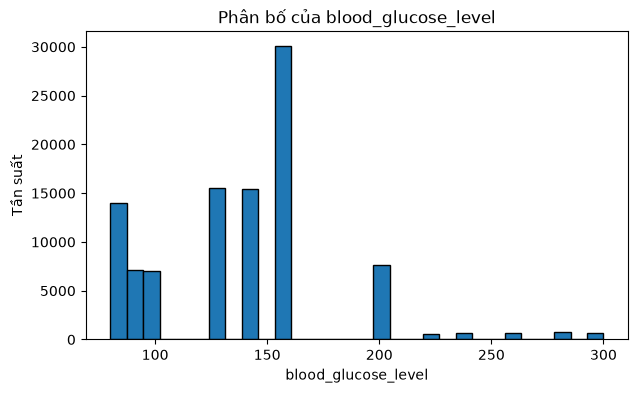

In [13]:
important_features = [
    "age",
    "bmi",
    "hbA1c_level",
    "blood_glucose_level"
]

for col in important_features:
    plt.figure(figsize=(7, 4))

    plt.hist(
        df[col],
        bins=30,
        edgecolor="black"
    )

    plt.title(f"Phân bố của {col}")
    plt.xlabel(col)
    plt.ylabel("Tần suất")

    plt.show()

Các biến `age`, `bmi`, `hbA1c_level` và `blood_glucose_level` có phạm vi và phân phối khác nhau. Một số biến như BMI, HbA1c và đường huyết có các giá trị cao nằm xa phần lớn dữ liệu.
Những giá trị cao này có thể là các trường hợp bệnh nhân có tình trạng sức khỏe bất thường chứ không nhất thiết là lỗi dữ liệu.

In [15]:
group_summary = df.groupby("diabetes")[
    [
        "age",
        "bmi",
        "hbA1c_level",
        "blood_glucose_level"
    ]
].mean()

display(group_summary)

,age,bmi,hbA1c_level,blood_glucose_level
diabetes,,,,
0,40.114997,26.887097,5.396751,132.853267
1,60.946588,31.988382,6.934953,194.094706


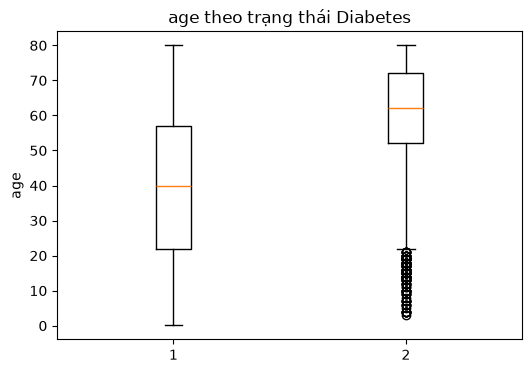

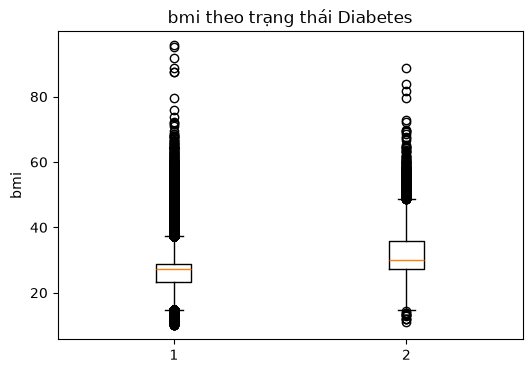

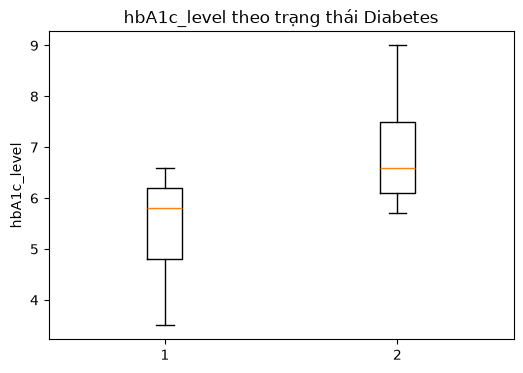

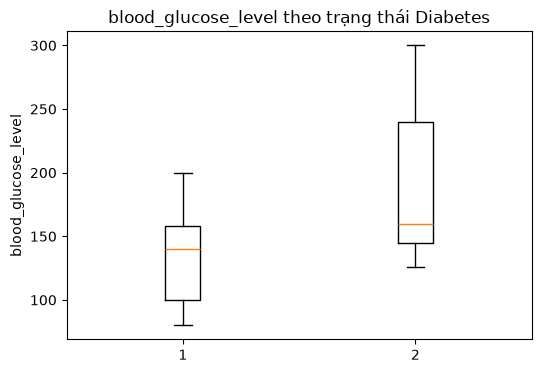

In [20]:
for col in [
    "age",
    "bmi",
    "hbA1c_level",
    "blood_glucose_level"
]:
    plt.figure(figsize=(6, 4))

    data_0 = df.loc[
        df["diabetes"] == 0,
        col
    ]

    data_1 = df.loc[
        df["diabetes"] == 1,
        col
    ]

    plt.boxplot(
        [data_0, data_1],
        label=["Không mắc", "Mắc"]
    )

    plt.title(f"{col} theo trạng thái Diabetes")
    plt.ylabel(col)

    plt.show()

Nhóm mắc tiểu đường có giá trị trung bình cao hơn rõ rệt ở nhiều đặc trưng:

- Tuổi: khoảng **60,95** so với **40,12**.
- BMI: khoảng **31,99** so với **26,89**.
- HbA1c: khoảng **6,94** so với **5,40**.
- Blood glucose: khoảng **194,10** so với **132,85**.

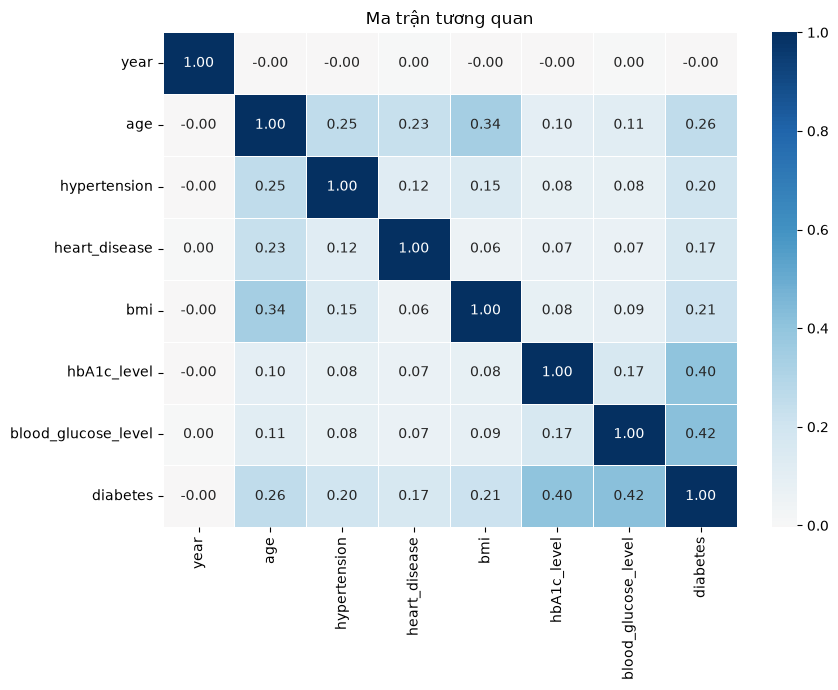

diabetes               1.000000
blood_glucose_level    0.419574
hbA1c_level            0.400688
age                    0.258032
bmi                    0.214359
hypertension           0.197814
heart_disease          0.171720
year                  -0.003444
Name: diabetes, dtype: float64


In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_cols = [
    "year",
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "hbA1c_level",
    "blood_glucose_level",
    "diabetes"
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    linewidths=0.5
)

plt.title("Ma trận tương quan")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(
    corr_matrix["diabetes"]
    .sort_values(ascending=False)
)

Các biến có tương quan dương đáng chú ý nhất với `diabetes` là:

- `blood_glucose_level`: khoảng **0,42**
- `hbA1c_level`: khoảng **0,40**
- `age`: khoảng **0,26**
- `bmi`: khoảng **0,21**
- `hypertension`: khoảng **0,20**
- `heart_disease`: khoảng **0,17**

Đường huyết và HbA1c có mối liên hệ mạnh nhất với trạng thái tiểu đường trong các biến số được khảo sát.

## 11. Xác định đặc trưng và biến mục tiêu

In [27]:
TARGET = "diabetes"

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (99986, 15)
y shape: (99986,)


## 12. Biểu diễn dữ liệu

In [28]:
# Tách feature và target
X = df.drop(columns=["diabetes"])
y = df["diabetes"]

print("Original DataFrame shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

# Hiển thị một bản ghi gốc
display(df.iloc[[0]])

Original DataFrame shape: (99986, 16)
Feature matrix shape: (99986, 15)
Target shape: (99986,)


,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0


In [30]:
# Feature vector ban đầu của một bệnh nhân
sample = X.iloc[0]

print("Feature vector của bệnh nhân đầu tiên:")
print(sample)

print("\nSố đặc trưng:", X.shape[1])

Feature vector của bệnh nhân đầu tiên:
year                       2020
gender                   Female
age                        32.0
location                Alabama
race:AfricanAmerican          0
race:Asian                    0
race:Caucasian                0
race:Hispanic                 0
race:Other                    1
hypertension                  0
heart_disease                 0
smoking_history           never
bmi                       27.32
hbA1c_level                 5.0
blood_glucose_level         100
Name: 0, dtype: object

Số đặc trưng: 15


## 13. Feature Engineering

Hai đặc trưng mới được tạo:

- `cardio_risk`: tổng thông tin tăng huyết áp và bệnh tim.
- `glucose_hba1c_interaction`: tương tác giữa mức đường huyết và HbA1c.

Các đặc trưng mới chỉ được tính từ thông tin của chính bệnh nhân nên không sử dụng thông tin từ biến mục tiêu và không gây data leakage.

In [31]:
def add_features(data):
    data = data.copy()

    data["cardio_risk"] = (
        data["hypertension"]
        + data["heart_disease"]
    )

    data["glucose_hba1c_interaction"] = (
        data["blood_glucose_level"]
        * data["hbA1c_level"]
    )

    return data

## 14. Train/Validation/Test Split

Dữ liệu được chia theo tỷ lệ:

- **70% Train:** dùng để huấn luyện mô hình.
- **15% Validation:** dùng để so sánh và lựa chọn mô hình.
- **15% Test:** chỉ sử dụng sau khi đã chọn mô hình cuối cùng.

In [32]:
from sklearn.model_selection import train_test_split

# 70% train, 30% tạm thời
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Chia 30% thành 15% validation + 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTỷ lệ diabetes:")

print("Train:")
print(y_train.value_counts(normalize=True))

print("\nValidation:")
print(y_val.value_counts(normalize=True))

print("\nTest:")
print(y_test.value_counts(normalize=True))

Train: (69990, 15)
Validation: (14998, 15)
Test: (14998, 15)

Tỷ lệ diabetes:
Train:
diabetes
0    0.914988
1    0.085012
Name: proportion, dtype: float64

Validation:
diabetes
0    0.914989
1    0.085011
Name: proportion, dtype: float64

Test:
diabetes
0    0.914989
1    0.085011
Name: proportion, dtype: float64


## 15. Preprocessing pipeline

Các nhóm đặc trưng được xử lý khác nhau:

### Biến số liên tục
- Điền missing value bằng median.
- Chuẩn hóa bằng StandardScaler.

### Biến phân loại
- Điền missing value bằng giá trị phổ biến nhất.
- Chuyển sang dạng số bằng One-Hot Encoding.

### Biến nhị phân
Các biến đã có dạng 0/1 được giữ nguyên.


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer


categorical_features = [
    "gender",
    "location",
    "smoking_history"
]

binary_features = [
    "race:AfricanAmerican",
    "race:Asian",
    "race:Caucasian",
    "race:Hispanic",
    "race:Other",
    "hypertension",
    "heart_disease"
]

numeric_features = [
    "year",
    "age",
    "bmi",
    "hbA1c_level",
    "blood_glucose_level",
    "cardio_risk",
    "glucose_hba1c_interaction"
]


numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])


categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])


preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
    (
        "binary",
        "passthrough",
        binary_features
    )
])

## 16. Baseline model

Mô hình baseline luôn dự đoán lớp phổ biến nhất. Vì khoảng 91,5% bệnh nhân không mắc tiểu đường nên baseline có thể đạt Accuracy cao nhưng Recall cho lớp mắc bệnh bằng 0.

Điều này cho thấy tại sao Accuracy không đủ để đánh giá bài toán mất cân bằng.

In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_val)

print(
    "Accuracy:",
    accuracy_score(y_val, baseline_pred)
)

print(
    "Precision:",
    precision_score(
        y_val,
        baseline_pred,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_val,
        baseline_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_val,
        baseline_pred,
        zero_division=0
    )
)

Accuracy: 0.914988665155354
Precision: 0.0
Recall: 0.0
F1: 0.0


## 17. Model training

5 mô hình được xây dựng và so sánh:

- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine
- K-Nearest Neighbors

In [42]:
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier


models = {
    "Logistic Regression":
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=8,
            class_weight="balanced",
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),

    "SVM":
        LinearSVC(
            class_weight="balanced",
            random_state=42
        ),

    "KNN":
        KNeighborsClassifier(
            n_neighbors=7,
            weights="distance"
        )
}

In [43]:
trained_models = {}

for name, estimator in models.items():

    pipeline = Pipeline([
        (
            "feature_engineering",
            FunctionTransformer(
                add_features,
                validate=False
            )
        ),
        (
            "preprocessing",
            clone(preprocessor)
        ),
        (
            "model",
            clone(estimator)
        )
    ])

    pipeline.fit(
        X_train,
        y_train
    )

    trained_models[name] = pipeline

    print(f"Đã huấn luyện: {name}")

Đã huấn luyện: Logistic Regression
Đã huấn luyện: Decision Tree
Đã huấn luyện: Random Forest
Đã huấn luyện: SVM
Đã huấn luyện: KNN


## 18. Model comparison

Các mô hình được so sánh bằng:

- **Accuracy:** tỷ lệ dự đoán đúng tổng thể.
- **Precision:** trong các bệnh nhân được dự đoán mắc bệnh, có bao nhiêu người thực sự mắc.
- **Recall:** trong các bệnh nhân thực sự mắc bệnh, mô hình phát hiện được bao nhiêu.
- **F1-score:** trung bình điều hòa giữa Precision và Recall.
- **ROC-AUC:** khả năng phân biệt giữa hai lớp.

In [44]:
from sklearn.metrics import roc_auc_score

validation_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_val)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(
            X_val
        )[:, 1]

    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(
            X_val
        )

    else:
        y_score = y_pred

    validation_results.append({
        "Model": name,

        "Accuracy":
            accuracy_score(
                y_val,
                y_pred
            ),

        "Precision":
            precision_score(
                y_val,
                y_pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_val,
                y_pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_val,
                y_pred,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y_val,
                y_score
            )
    })


comparison_df = pd.DataFrame(
    validation_results
)

comparison_df = comparison_df.sort_values(
    "F1",
    ascending=False
)

display(comparison_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Random Forest,0.964929,0.826504,0.743529,0.782824,0.973575
4,KNN,0.959861,0.928662,0.571765,0.707767,0.912104
1,Decision Tree,0.911055,0.487246,0.883922,0.628205,0.972967
3,SVM,0.888385,0.424632,0.881569,0.573177,0.962379
0,Logistic Regression,0.888385,0.424575,0.880784,0.572959,0.962405


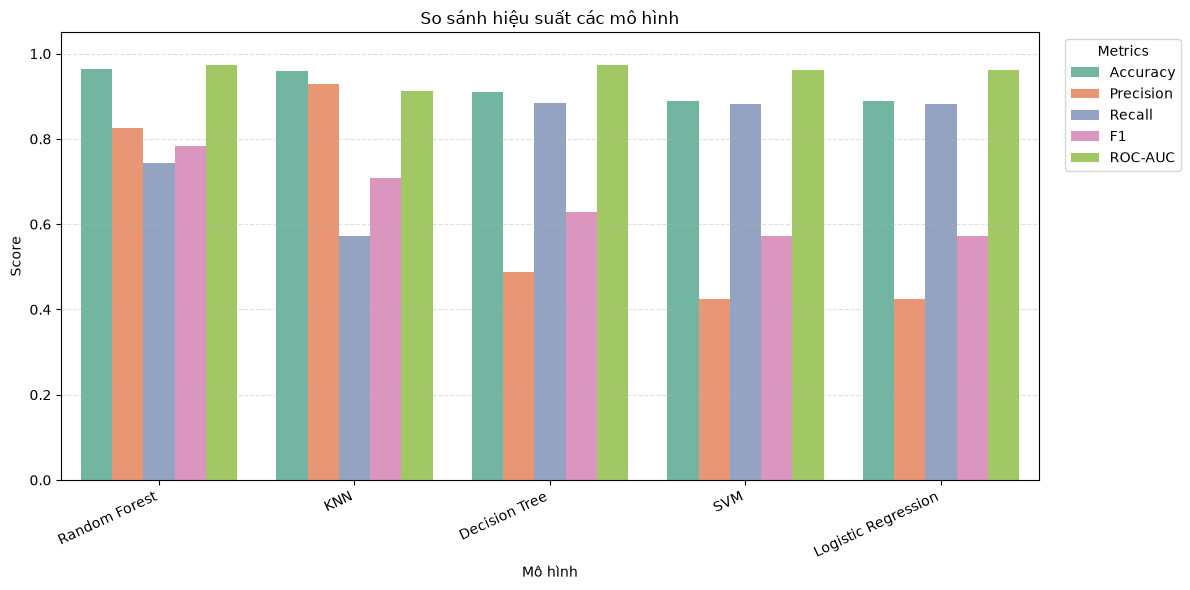

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

# Chuyển DataFrame từ dạng rộng sang dạng dài
plot_df = comparison_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("So sánh hiệu suất các mô hình")
plt.xlabel("Mô hình")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=25, ha="right")

plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

Biểu đồ cho thấy **Random Forest** có hiệu suất tổng thể tốt nhất với:

- Accuracy: **0.9649**
- Precision: **0.8265**
- Recall: **0.7435**
- F1-score: **0.7828**
- ROC-AUC: **0.9736**

Đây là mô hình có **F1-score cao nhất**, đồng thời duy trì Accuracy và ROC-AUC rất cao, nên có sự cân bằng tốt giữa khả năng dự đoán chính xác và khả năng phát hiện bệnh nhân mắc tiểu đường.

**KNN** có Precision cao nhất (**0.9287**), nghĩa là khi mô hình dự đoán một bệnh nhân mắc tiểu đường thì thường rất chính xác. Tuy nhiên, Recall chỉ khoảng **0.5718**, cho thấy mô hình bỏ sót khá nhiều bệnh nhân thực sự mắc bệnh.

**Decision Tree** có Recall cao (**0.8839**), tức là phát hiện được phần lớn bệnh nhân mắc tiểu đường. Tuy nhiên Precision chỉ **0.4872**, nên tạo ra nhiều dự đoán dương tính giả.

**SVM** và **Logistic Regression** có kết quả gần như tương đương. Cả hai đều có Recall cao khoảng **0.88**, nhưng Precision thấp khoảng **0.42**, dẫn đến F1-score thấp hơn Random Forest.

## 19. Evaluation

Mô hình: Random Forest
Accuracy : 0.9649286571542872
Precision: 0.8265039232781168
Recall   : 0.7435294117647059
F1-score : 0.782824112303881
ROC-AUC  : 0.9735754915534675

Classification Report:
              precision    recall  f1-score   support

           0     0.9764    0.9855    0.9809     13723
           1     0.8265    0.7435    0.7828      1275

    accuracy                         0.9649     14998
   macro avg     0.9014    0.8645    0.8819     14998
weighted avg     0.9636    0.9649    0.9641     14998



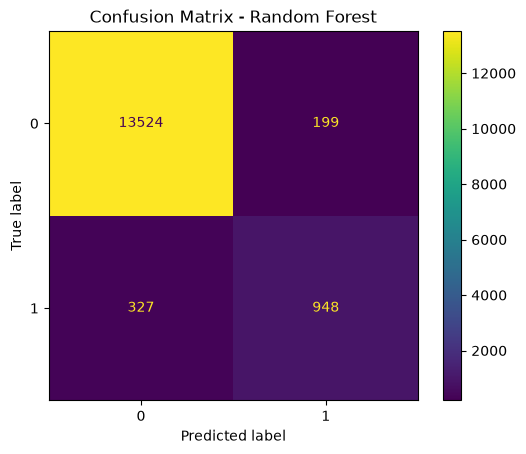

In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Mô hình tốt nhất hiện tại dựa trên F1-score
candidate_name = comparison_df.iloc[0]["Model"]
candidate_model = trained_models[candidate_name]

# Dự đoán trên Validation Set
val_pred = candidate_model.predict(X_val)

if hasattr(candidate_model, "predict_proba"):
    val_score = candidate_model.predict_proba(X_val)[:, 1]
else:
    val_score = candidate_model.decision_function(X_val)

print("Mô hình:", candidate_name)

print("Accuracy :", accuracy_score(y_val, val_pred))
print("Precision:", precision_score(y_val, val_pred))
print("Recall   :", recall_score(y_val, val_pred))
print("F1-score :", f1_score(y_val, val_pred))
print("ROC-AUC  :", roc_auc_score(y_val, val_score))

print("\nClassification Report:")
print(classification_report(y_val, val_pred, digits=4))

cm = confusion_matrix(y_val, val_pred)

ConfusionMatrixDisplay(cm).plot()
plt.title(f"Confusion Matrix - {candidate_name}")
plt.show()

onfusion Matrix cho biết:

- **True Positive:** dự đoán đúng bệnh nhân mắc bệnh.
- **True Negative:** dự đoán đúng bệnh nhân không mắc bệnh.
- **False Positive:** dự đoán mắc bệnh nhưng thực tế không mắc.
- **False Negative:** bệnh nhân mắc bệnh nhưng mô hình không phát hiện.

Trong bài toán y tế, **False Negative cần được đặc biệt chú ý** vì đây là các bệnh nhân mắc bệnh nhưng bị bỏ sót.

## 20. Phân tích lỗi

Phân tích lỗi giúp tìm hiểu những trường hợp mô hình dự đoán sai.

Hai loại lỗi chính:

- **False Positive:** thực tế không mắc bệnh nhưng mô hình dự đoán mắc bệnh.
- **False Negative:** thực tế mắc bệnh nhưng mô hình dự đoán không mắc bệnh.

In [49]:
error_df = X_val.copy()

error_df["Actual"] = y_val.values
error_df["Predicted"] = val_pred

false_positive = error_df[
    (error_df["Actual"] == 0) &
    (error_df["Predicted"] == 1)
]

false_negative = error_df[
    (error_df["Actual"] == 1) &
    (error_df["Predicted"] == 0)
]

print("False Positive:", len(false_positive))
print("False Negative:", len(false_negative))

False Positive: 199
False Negative: 327


In [50]:
display(
    false_negative[
        [
            "age",
            "bmi",
            "hbA1c_level",
            "blood_glucose_level",
            "hypertension",
            "heart_disease",
            "Actual",
            "Predicted"
        ]
    ].head(20)
)

,age,bmi,hbA1c_level,blood_glucose_level,hypertension,heart_disease,Actual,Predicted
79884,76.0,31.75,5.8,160,0,0,1,0
64717,40.0,25.59,6.0,200,0,0,1,0
52479,80.0,29.99,6.0,130,0,0,1,0
52686,43.0,27.84,5.7,145,0,0,1,0
47796,42.0,45.36,6.6,145,0,0,1,0
99422,60.0,33.56,6.0,155,0,0,1,0
43737,45.0,40.52,6.0,155,0,0,1,0
89280,73.0,38.49,5.8,130,0,0,1,0
51153,47.0,27.32,6.0,145,0,0,1,0
16646,66.0,31.59,6.1,126,0,0,1,0


Error Type
Correct           14472
False Negative      327
False Positive      199
Name: count, dtype: int64


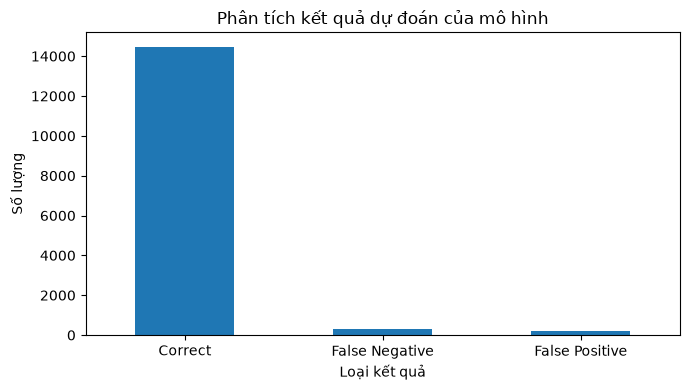

In [51]:
# Tạo nhãn loại kết quả
error_df["Error Type"] = np.select(
    [
        (error_df["Actual"] == 0) & (error_df["Predicted"] == 1),
        (error_df["Actual"] == 1) & (error_df["Predicted"] == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correct"
)

# Đếm số lượng
error_counts = error_df["Error Type"].value_counts()

print(error_counts)

# Vẽ biểu đồ
plt.figure(figsize=(7, 4))

error_counts.plot(kind="bar")

plt.title("Phân tích kết quả dự đoán của mô hình")
plt.xlabel("Loại kết quả")
plt.ylabel("Số lượng")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Các trường hợp False Negative thường là những bệnh nhân có đặc điểm gần với nhóm không mắc bệnh, khiến mô hình khó phân biệt.

Việc phân tích nhóm này giúp đánh giá điểm yếu của mô hình và xác định liệu mô hình có bỏ sót quá nhiều bệnh nhân thực sự mắc tiểu đường hay không.

## 21. Chọn mô hình

Mô hình cuối cùng được lựa chọn dựa trên kết quả của tập Validation.

Tiêu chí chính là **F1-score**, đồng thời xem xét:

- Recall
- Precision
- ROC-AUC
- Số lượng False Negative

Mô hình được chọn cần đạt sự cân bằng tốt giữa khả năng phát hiện bệnh nhân mắc bệnh và hạn chế dự đoán sai.

In [52]:
best_row = comparison_df.sort_values(
    "F1",
    ascending=False
).iloc[0]

best_model_name = best_row["Model"]

print("Mô hình được chọn:", best_model_name)

display(best_row.to_frame().T)

Mô hình được chọn: Random Forest


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Random Forest,0.964929,0.826504,0.743529,0.782824,0.973575


In [53]:
from sklearn.base import clone

X_train_final = pd.concat(
    [X_train, X_val],
    axis=0
)

y_train_final = pd.concat(
    [y_train, y_val],
    axis=0
)

final_model = Pipeline([
    (
        "feature_engineering",
        FunctionTransformer(
            add_features,
            validate=False
        )
    ),
    (
        "preprocessing",
        clone(preprocessor)
    ),
    (
        "model",
        clone(models[best_model_name])
    )
])

final_model.fit(
    X_train_final,
    y_train_final
)

print("Đã train lại:", best_model_name)
print("Training data:", X_train_final.shape)

Đã train lại: Random Forest
Training data: (84988, 15)


FINAL TEST RESULTS
-------------------
Accuracy : 0.9629950660088011
Precision: 0.8185840707964602
Recall   : 0.7254901960784313
F1-score : 0.7692307692307693
ROC-AUC  : 0.9719481391623909


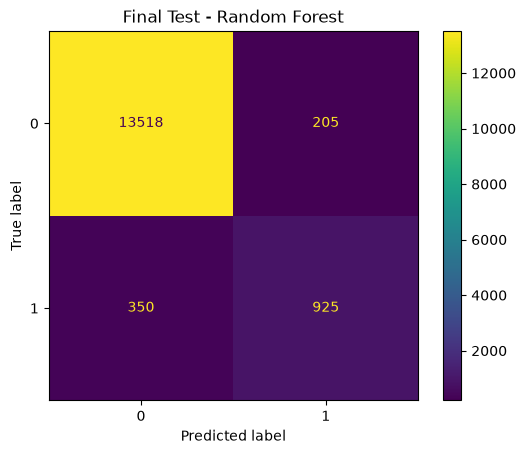

In [54]:
test_pred = final_model.predict(X_test)

if hasattr(final_model, "predict_proba"):
    test_score = final_model.predict_proba(X_test)[:, 1]
else:
    test_score = final_model.decision_function(X_test)

print("FINAL TEST RESULTS")
print("-------------------")

print("Accuracy :", accuracy_score(y_test, test_pred))
print("Precision:", precision_score(y_test, test_pred))
print("Recall   :", recall_score(y_test, test_pred))
print("F1-score :", f1_score(y_test, test_pred))
print("ROC-AUC  :", roc_auc_score(y_test, test_score))

cm_test = confusion_matrix(y_test, test_pred)

ConfusionMatrixDisplay(cm_test).plot()
plt.title(f"Final Test - {best_model_name}")
plt.show()

## 22. Lưu mô hình

In [55]:
import joblib

model_bundle = {
    "model_name": best_model_name,
    "pipeline": final_model,
    "target": "diabetes",
    "input_features": X.columns.tolist()
}

joblib.dump(
    model_bundle,
    "diabetes_model.joblib"
)

print("Đã lưu mô hình: diabetes_model.joblib")

Đã lưu mô hình: diabetes_model.joblib


## 23. Inference test

In [56]:
saved_model = joblib.load(
    "diabetes_model.joblib"
)

loaded_model = saved_model["pipeline"]

print(
    "Loaded model:",
    saved_model["model_name"]
)

Loaded model: Random Forest


In [57]:
new_patient = pd.DataFrame({
    "year": [2022],
    "gender": ["Female"],
    "age": [55],
    "location": ["Alabama"],

    "race:AfricanAmerican": [0],
    "race:Asian": [0],
    "race:Caucasian": [1],
    "race:Hispanic": [0],
    "race:Other": [0],

    "hypertension": [1],
    "heart_disease": [0],

    "smoking_history": ["former"],

    "bmi": [31.5],
    "hbA1c_level": [6.8],
    "blood_glucose_level": [180]
})

display(new_patient)

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level
0,2022,Female,55,Alabama,0,0,1,0,0,1,0,former,31.5,6.8,180


In [58]:
prediction = loaded_model.predict(
    new_patient
)[0]

print("Prediction:", prediction)

if hasattr(loaded_model, "predict_proba"):

    probability = loaded_model.predict_proba(
        new_patient
    )[0, 1]

    print(
        "Probability:",
        round(probability, 4)
    )

if prediction == 1:
    print("Kết quả: Dự đoán mắc tiểu đường")
else:
    print("Kết quả: Dự đoán không mắc tiểu đường")

Prediction: 1
Probability: 0.845
Kết quả: Dự đoán mắc tiểu đường
